# What Reviews Reveal About Skin-Type Fit
### Mining Sephora moisturizer reviews to improve skincare quiz recommendations

**Neha Kollikara · INFO 4360 Final Project · Path B: Understanding/Extraction**

## Setup

In [2]:
# Reload src/ functions automatically when they change
%load_ext autoreload
%autoreload 2

# Imports
import os
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.utils import load_data, plot_bar, plot_barh, clean_axes
from scipy.stats import fisher_exact
from matplotlib.colors import LinearSegmentedColormap

In [3]:
# Complaint categories, in the order used for labeling (notebook 4), with readable names for charts
CATEGORY_NAMES = {
    "greasy_heavy": "Greasy / Heavy",
    "breakouts": "Breakouts",
    "not_moisturizing": "Not Moisturizing",
    "irritation": "Irritation",
    "fragrance": "Fragrance",
    "pilling": "Pilling",
    "no_results": "No Results",
    "price_value": "Price / Value",
    "packaging": "Packaging",
    "reformulation": "Reformulation",
    "other": "Other",
}
CATEGORIES = list(CATEGORY_NAMES)

# Skin types ordered from dry to oily, with display names and one consistent color each
SKIN_ORDER = ["dry", "normal", "combination", "oily"]
SKIN_LABELS = {s: s.title() for s in SKIN_ORDER}
SKIN_COLORS = {"dry": "#C8325A", "normal": "#E89AAE", "combination": "#B7A6AB", "oily": "#1A1A1A"}

# Load Claude's labels and drop the 3 reviews that couldn't be labeled (notebook 4)
labeled = pd.read_csv("../Data/claude_labels.csv", dtype={"review_id": str},
                      parse_dates=["submission_time"])
labeled = labeled.dropna(subset=["any_complaint"]).copy()
labeled[CATEGORIES + ["any_complaint"]] = labeled[CATEGORIES + ["any_complaint"]].astype(int)
print(f"Labeled reviews: {len(labeled):,}")
print(labeled.groupby("skin_type").size())

Labeled reviews: 7,997
skin_type
combination    1999
dry            2000
normal         2000
oily           1998
dtype: int64


## 1. Problem Statement

## 2. Data and Descriptive Analysis

## 3. Text Analysis

## 4. Tool Integration: Labeling Complaints with Claude

## 5. Complaint Analysis: Which Complaints Concentrate in Which Skin Types?

**Approach:** Claude labeled each of the 7,997 sampled reviews with zero or more complaint categories (Section 4). For each category, the complaint rate is the share of reviews that mention it. Rates are used instead of counts because they are comparable across groups. The sample has an equal number of reviews per product and skin type, so skin types can be compared fairly.

The analysis starts broad, with complaint rates overall and by skin type across all 20 products combined, and then narrows to individual products, where the recommendations come from.

### 5.1 Overall Complaint Rates and Differences by Skin Type

Reviews with at least one complaint: 35.9%


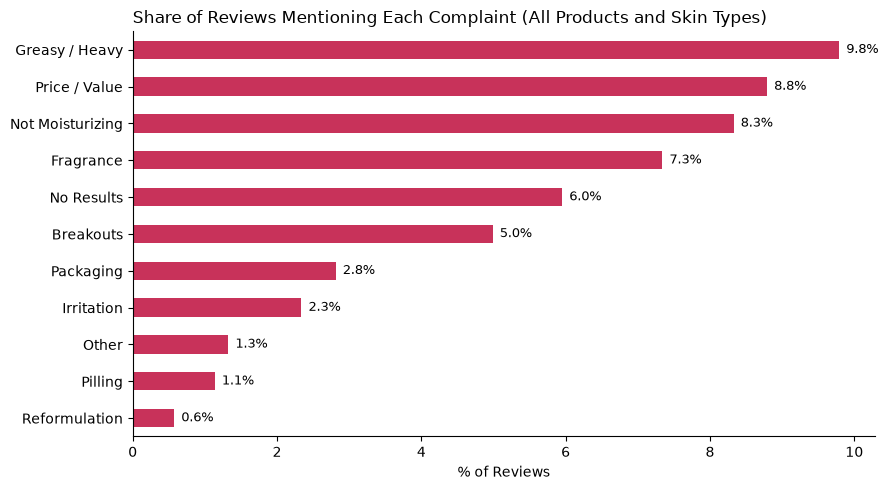

In [4]:
# Share of reviews mentioning each complaint, across the whole sample
overall = (labeled[CATEGORIES].mean() * 100).rename(CATEGORY_NAMES).sort_values()
print(f"Reviews with at least one complaint: {labeled['any_complaint'].mean():.1%}")

# Horizontal bar chart, largest complaint at the top
plot_barh(overall, "Share of Reviews Mentioning Each Complaint (All Products and Skin Types)",
          "% of Reviews", fmt="{:.1f}%", save_path="../Figures/overall_complaint_rates.png")

skin_type,dry,normal,combination,oily
Greasy / Heavy,6.6,9.8,10.6,12.1
Breakouts,4.0,5.1,5.6,5.4
Not Moisturizing,11.6,8.2,8.4,5.1
Irritation,2.6,2.0,2.6,2.3
Fragrance,7.0,7.8,7.4,7.3
Pilling,1.1,1.2,1.2,1.1
No Results,5.4,6.0,6.7,5.8
Price / Value,9.4,8.5,9.0,8.4
Packaging,3.4,2.5,3.3,2.1
Reformulation,0.6,0.6,0.6,0.5


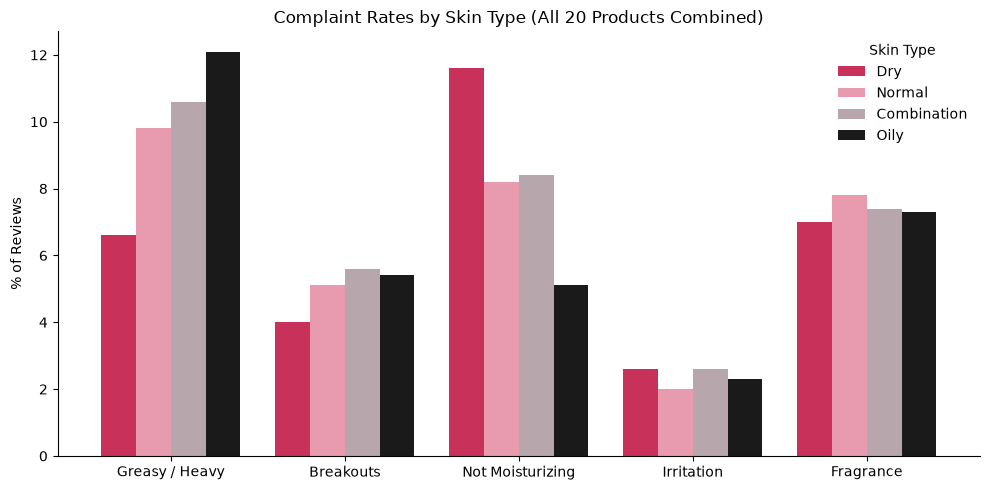

In [5]:
# Complaint rates by skin type, all 20 products combined
by_skin = (labeled.groupby("skin_type")[CATEGORIES + ["any_complaint"]].mean() * 100).T
by_skin = by_skin[SKIN_ORDER].rename(index=CATEGORY_NAMES | {"any_complaint": "Any complaint"}).round(1)
display(by_skin)

# Grouped bar chart for the complaints most related to skin-type fit
skin_fit = ["Greasy / Heavy", "Breakouts", "Not Moisturizing", "Irritation", "Fragrance"]
ax = (by_skin.loc[skin_fit].rename(columns=SKIN_LABELS)
      .plot(kind="bar", color=[SKIN_COLORS[s] for s in SKIN_ORDER], figsize=(10, 5), rot=0, width=0.8))
ax.set_title("Complaint Rates by Skin Type (All 20 Products Combined)")
ax.set_ylabel("% of Reviews")
ax.legend(title="Skin Type", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../Figures/complaint_rates_by_skin_type.png", dpi=200, bbox_inches="tight")
plt.show()

**Observations**

About a third of reviews contain a complaint with 35.9% of reviews mentioning at least one complaint, even though most reviews in the sample are positive. Many complaints appear inside otherwise favorable reviews ("love it, but…"), which is why every review was labeled rather than only low-rated ones.

**Most common complaints:** greasy/heavy texture (9.8% of reviews), price/value (8.8%), not moisturizing enough (8.3%), and fragrance (7.3%), followed by no results (6.0%) and breakouts (5.0%). Packaging, irritation, pilling, reformulation, and other each appear in under 3% of reviews. At that rate, a product–skin type group of about 100 reviews would contain only one to three mentions, too few to compare reliably, so the product-level analysis below focuses on the six most common categories. Since Claude over-applied "no results" in the agreement test (Section 4), its 6.0% rate is an upper bound.

**Skin types complain about opposite things:** With 2,000 reviews per skin type, differences under about 2 percentage points are within normal sampling variation. The differences for texture and moisture are well beyond that:
- Greasy/heavy complaints rise steadily from dry to oily skin: 6.6% (dry), 9.8% (normal), 10.6% (combination), 12.1% (oily). Oily-skin reviewers mention greasiness almost twice as often as dry-skin reviewers.
- Not moisturizing complaints run in the opposite direction: 11.6% (dry), 8.2% (normal), 8.4% (combination), 5.1% (oily). Dry-skin reviewers mention it more than twice as often as oily-skin reviewers.
- Breakouts are slightly less common for dry skin (4.0%) than for the other types (5.1–5.6%), a smaller gap near the edge of sampling noise.

**Some complaints don't depend on skin type:** Fragrance (7.0–7.8%), price (8.4–9.4%), irritation (2.0–2.6%), and the overall share of reviews with any complaint (34.8–37.2%) are nearly identical across skin types. Shoppers of every skin type are about equally likely to be dissatisfied, but the reason differs by skin type, which is exactly the information the skincare quiz could use. Complaints that don't vary by skin type, like fragrance, are product-level issues better handled through filters (for example, fragrance-free) than through skin-type quiz rules.

**Why look at individual products next?** These rates combine all 20 products, so they show a general tendency rather than which specific products to adjust. The next step compares skin types within each product, where the quiz recommendations come from.

### 5.2 Comparing Skin Types Within Each Product

The pooled results show a general tendency, but quiz rules need to be product-specific. For each of the 20 products, complaint rates are compared between oily-skin and dry-skin reviewers (about 100 reviews each). This comparison was chosen in advance: oily and dry skin sit at opposite ends of the spectrum, showed the largest pooled gaps, and translate into the clearest quiz rules.

The comparison focuses on the three complaints most tied to how a product suits the skin: greasy/heavy, not moisturizing, and breakouts. Fragrance and price did not differ by skin type in the pooled results, and the remaining categories are too rare to compare at the product level.

**Which gaps are real?** Each oily-vs-dry gap is tested with Fisher's exact test, which suits small counts. Because 60 gaps are tested (20 products × 3 complaints), some would look significant by chance alone, so p-values are adjusted with the Benjamini-Hochberg correction, which keeps the expected share of false findings below 5%. Only gaps with an adjusted p-value (q-value) below 0.05 are reported as findings. With about 100 reviews per group, this generally requires a gap of roughly 10 percentage points or more.

In [14]:
# Short product labels for charts: brand plus the first few words of the product name,
# dropping a dangling "with", "&", or "+" at the end
labeled["product_label"] = (labeled["brand_name"] + " – "
                            + labeled["product_name"].str.split().str[:4].str.join(" ")
                              .str.replace(r"\s+(with|&|\+)$", "", regex=True))

# The three complaints compared at the product level
FOCUS = ["greasy_heavy", "not_moisturizing", "breakouts"]

# Complaint rate (%) for every product and skin type
rates = labeled.groupby(["product_label", "skin_type"])[FOCUS].mean() * 100
group_sizes = labeled.groupby(["product_label", "skin_type"]).size()
print(f"Reviews per product and skin type: {group_sizes.min()} to {group_sizes.max()}")

# Short display names for charts, so long product names don't crowd out the data
SHORT_NAMES = {
    "belif – The True Cream Aqua": "belif Aqua Bomb",
    "belif – The True Cream Moisturizing": "belif Moisturizing Bomb",
    "Biossance – Squalane + Omega Repair": "Biossance Omega Repair",
    "Charlotte Tilbury – Magic Cream Moisturizer": "Charlotte Tilbury Magic Cream",
    "CLINIQUE – Dramatically Different Moisturizing Gel": "CLINIQUE Moisturizing Gel",
    "Drunk Elephant – Lala Retro Whipped Refillable": "Drunk Elephant Lala Retro",
    "Drunk Elephant – Protini Polypeptide Firming Refillable": "Drunk Elephant Protini",
    "Estée Lauder – Revitalizing Supreme+ Youth Power": "Estée Lauder Revitalizing Supreme+",
    "First Aid Beauty – Ultra Repair Cream Intense": "First Aid Beauty Ultra Repair",
    "Glow Recipe – Watermelon Pink Juice Oil-Free": "Glow Recipe Watermelon Pink Juice",
    "IT Cosmetics – Confidence in a Cream": "IT Cosmetics Confidence in a Cream",
    "Kiehl's Since 1851 – Ultra Facial Moisturizing Cream": "Kiehl's Ultra Facial Cream",
    "KORRES – Greek Yoghurt Nourishing Probiotic": "KORRES Greek Yoghurt",
    "KORRES – Santorini Grape Poreless Skin": "KORRES Santorini Grape",
    "OLEHENRIKSEN – C-Rush Vitamin C Gel": "OLEHENRIKSEN C-Rush Gel",
    "Origins – Original Skin Matte Moisturizer": "Origins Matte Moisturizer",
    "Skinfix – Barrier+ Triple Lipid-Peptide Face": "Skinfix Barrier+",
    "Tatcha – The Dewy Skin Cream": "Tatcha Dewy Skin Cream",
    "Tatcha – The Water Cream Oil-Free": "Tatcha Water Cream",
    "Youth To The People – Adaptogen Deep Moisturizing Cream": "Youth To The People Adaptogen",
}

def short(product):
    """Short display name for a product, falling back to the full label if it's not in the list."""
    return SHORT_NAMES.get(product, product)

Reviews per product and skin type: 99 to 100


In [7]:
# Test every oily-vs-dry gap: 20 products x 3 complaints = 60 comparisons
rows = []
for product, group in labeled.groupby("product_label"):
    oily = group[group["skin_type"] == "oily"]
    dry = group[group["skin_type"] == "dry"]
    for cat in FOCUS:
        o_yes, d_yes = oily[cat].sum(), dry[cat].sum()
        # 2x2 table: complaint yes/no for oily vs. dry reviewers
        _, p = fisher_exact([[o_yes, len(oily) - o_yes], [d_yes, len(dry) - d_yes]])
        rows.append({"product": product, "complaint": CATEGORY_NAMES[cat],
                     "oily_pct": o_yes / len(oily) * 100, "dry_pct": d_yes / len(dry) * 100,
                     "p_value": p})
gaps = pd.DataFrame(rows)
gaps["gap_pts"] = gaps["oily_pct"] - gaps["dry_pct"]

# Benjamini-Hochberg correction: adjust p-values for testing 60 gaps at once
gaps = gaps.sort_values("p_value").reset_index(drop=True)
m = len(gaps)
adjusted = gaps["p_value"].values * m / np.arange(1, m + 1)
gaps["q_value"] = np.minimum.accumulate(adjusted[::-1])[::-1].clip(max=1)
gaps["significant"] = gaps["q_value"] < 0.05

# How often the product-level gap points the same way as the pooled pattern
for cat in FOCUS:
    sub = gaps[gaps["complaint"] == CATEGORY_NAMES[cat]]
    print(f"{CATEGORY_NAMES[cat]}: oily > dry in {(sub['gap_pts'] > 0).sum()} of 20 products, "
          f"{sub['significant'].sum()} significant gaps")

# Significant gaps, largest first
display(gaps[gaps["significant"]]
        .sort_values("gap_pts", key=abs, ascending=False)
        [["product", "complaint", "oily_pct", "dry_pct", "gap_pts", "q_value"]]
        .round({"oily_pct": 1, "dry_pct": 1, "gap_pts": 1, "q_value": 4}))

Greasy / Heavy: oily > dry in 15 of 20 products, 1 significant gaps
Not Moisturizing: oily > dry in 4 of 20 products, 3 significant gaps
Breakouts: oily > dry in 13 of 20 products, 0 significant gaps


,product,complaint,oily_pct,dry_pct,gap_pts,q_value
0,CLINIQUE – Dramatically Different Moisturizing...,Not Moisturizing,6.0,33.0,-27.0,0.0001
1,Origins – Original Skin Matte Moisturizer,Not Moisturizing,5.1,29.0,-23.9,0.0002
2,Tatcha – The Water Cream Oil-Free,Not Moisturizing,7.0,26.0,-19.0,0.0092
3,Charlotte Tilbury – Magic Cream Moisturizer,Greasy / Heavy,19.0,4.0,15.0,0.0212


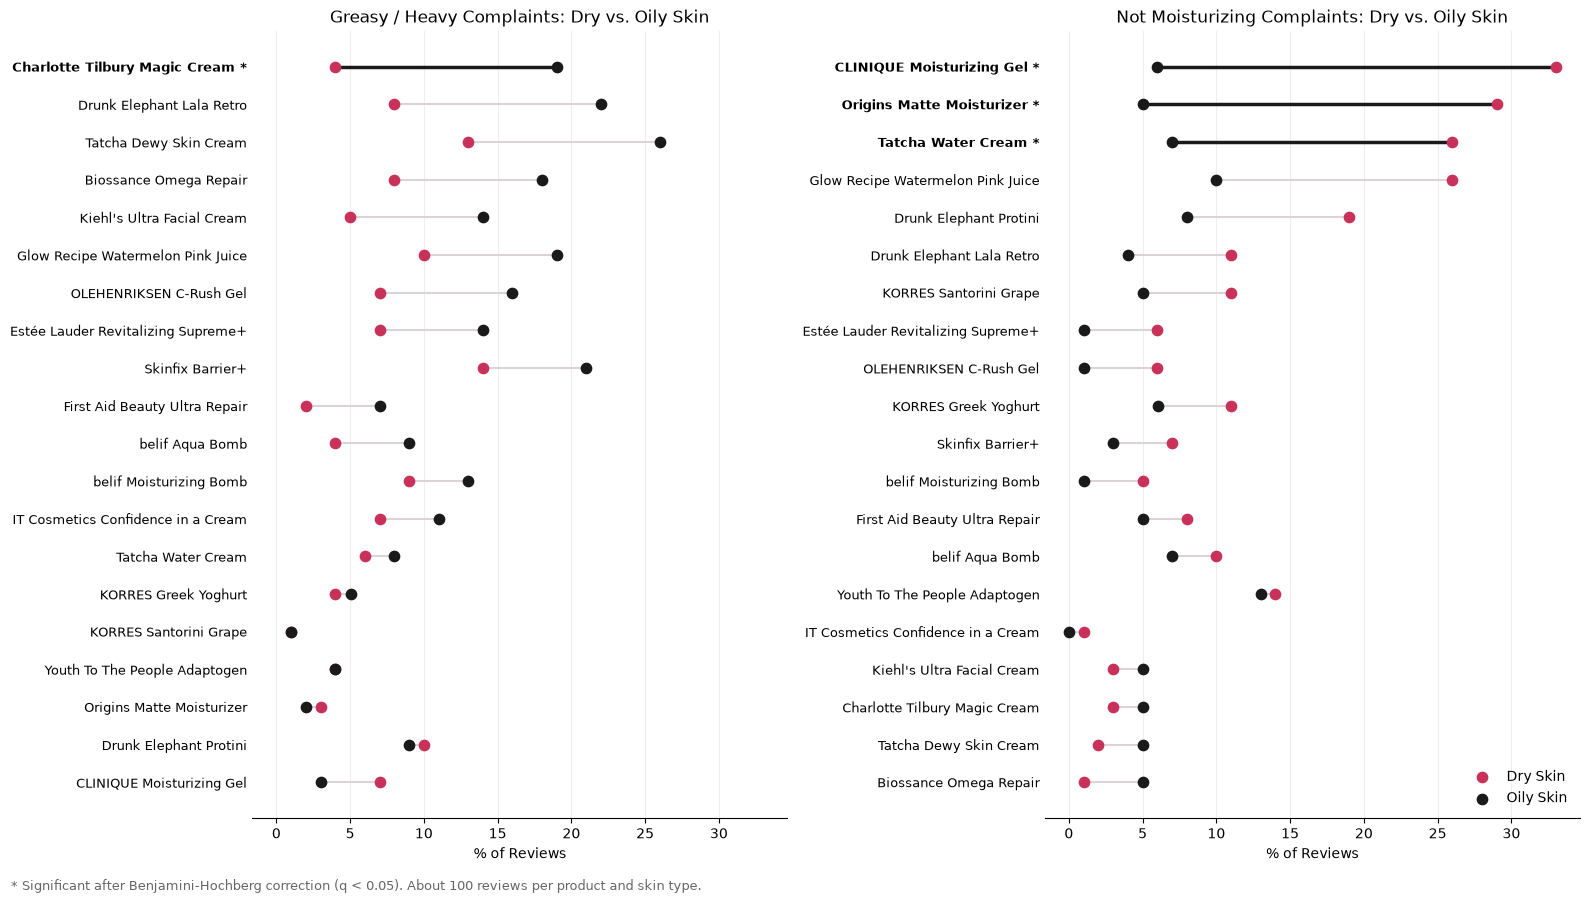

In [16]:
# Dumbbell chart: dry vs. oily complaint rate for each product, with significant gaps highlighted
def plot_dumbbell(category, ax, biggest_gap_first="oily"):
    name = CATEGORY_NAMES[category]
    table = rates[category].unstack()[["dry", "oily"]]
    # Sort so the largest gap in the expected direction sits at the top of the chart
    gap = table["oily"] - table["dry"]
    table = table.loc[gap.sort_values(ascending=(biggest_gap_first == "oily")).index]
    significant = set(gaps.loc[(gaps["complaint"] == name) & gaps["significant"], "product"])

    y = np.arange(len(table))
    # Connecting lines: dark for significant gaps, light gray for the rest
    for yi, (product, row) in zip(y, table.iterrows()):
        sig = product in significant
        ax.plot([row["dry"], row["oily"]], [yi, yi], color="#1A1A1A" if sig else "#DDD3D6",
                linewidth=2.5 if sig else 1.5, zorder=1)
    ax.scatter(table["dry"], y, s=55, color=SKIN_COLORS["dry"], label="Dry Skin", zorder=2)
    ax.scatter(table["oily"], y, s=55, color=SKIN_COLORS["oily"], label="Oily Skin", zorder=2)

    # Product names, with significant ones in bold and marked with *
    ax.set_yticks(y, [f"{short(p)} *" if p in significant else short(p) for p in table.index], fontsize=9)
    for label, product in zip(ax.get_yticklabels(), table.index):
        if product in significant:
            label.set_fontweight("bold")
    ax.set_title(f"{name} Complaints: Dry vs. Oily Skin")
    ax.set_xlabel("% of Reviews")
    ax.grid(axis="x", color="#EEEEEE")
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)


# Draw the chart: greasy (expected higher for oily) and not moisturizing (expected higher for dry)
fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharex=True)
plot_dumbbell("greasy_heavy", axes[0], biggest_gap_first="oily")
plot_dumbbell("not_moisturizing", axes[1], biggest_gap_first="dry")
axes[1].legend(frameon=False, loc="lower right")
fig.text(0.01, 0.005, "* Significant after Benjamini-Hochberg correction (q < 0.05). About 100 reviews per product and skin type.",
         fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig("../Figures/dumbbell_chart.png", dpi=200, bbox_inches="tight")
plt.show()

**Observations**

**The pooled pattern holds within individual products:** Oily-skin reviewers report more greasy/heavy complaints than dry-skin reviewers for 15 of 20 products, and dry-skin reviewers report more not-moisturizing complaints for 16 of 20. Breakouts lean slightly toward oily skin (13 of 20 products), but no single product's gap is large enough to be confirmed.

**Four product-level gaps are large enough to act on** (significant after correction, q < 0.05):

| Product | Complaint | Dry skin | Oily skin | Gap |
|---|---|---|---|---|
| Clinique Dramatically Different Moisturizing Gel | Not moisturizing | 33% | 6% | 27 pts |
| Origins Original Skin Matte Moisturizer | Not moisturizing | 29% | 5% | 24 pts |
| Tatcha The Water Cream (Oil-Free) | Not moisturizing | 26% | 7% | 19 pts |
| Charlotte Tilbury Magic Cream | Greasy/heavy | 4% | 19% | 15 pts |

**What the significant products have in common:** all three not-moisturizing findings are light, oil-free, or mattifying formulas, marketed partly to oily skin. Roughly one in three or four dry-skin reviewers found them not moisturizing enough, compared with about one in fifteen oily-skin reviewers. The greasy finding is the mirror image: Charlotte Tilbury's Magic Cream is a richer cream that oily-skin reviewers called greasy almost five times as often as dry-skin reviewers.

**The value is in the specifics, not the general idea:** It's well known that oily and dry skin need different moisturizers; what the reviews add is which products fail one skin type much more than the other, and by how much. Texture alone doesn't predict it as some light formulas (belif The True Cream Aqua Bomb, KORRES Greek Yoghurt gel-cream) show only small gaps, and First Aid Beauty's Ultra Repair Cream, a rich cream, is called greasy by just 7% of oily-skin reviewers. Other products show almost no skin-type gap at all, such as Youth To The People's Adaptogen cream (greasy: 4% of dry vs. 4% of oily reviewers; not moisturizing: 14% vs. 13%), which makes them safe to recommend regardless of skin type. Product-level evidence lets the quiz both steer shoppers away from specific poor matches and recommend products that work across skin types.

**Near misses:** a few gaps of 13–16 points point the same way but didn't pass the correction with about 100 reviews per group. Glow Recipe Watermelon Pink Juice Oil-Free came closest (not moisturizing: 26% of dry vs. 10% of oily reviewers, q = 0.06), followed by Tatcha The Dewy Skin Cream (greasy: 13% of dry vs. 26% of oily, q = 0.25). They're worth watching, and a larger sample for these products could confirm them, but they aren't reported as findings.

### 5.3 Do the gaps hold over time?

A gap could be an artifact of one period, for example a batch of reviews written right after a product launch or a formula change. Each finding is therefore recomputed separately in the earlier and later halves of that product's reviews, split at the product's own median review date. A single cutoff date for all products doesn't work here, because products were reviewed at different times: with one cutoff, some products had fewer than 10 reviews per skin type in a half. A finding is considered robust if the gap points the same direction, at a similar size, in both halves.

Each half has only about 50 reviews per skin type, so per-period rates are less precise, and the check focuses on direction and rough size rather than significance. The pooled oily-vs-dry pattern is also checked using a single cutoff for the whole sample, since it has about 1,000 reviews per skin type in each half.

In [9]:
# Split the whole sample into earlier and later halves at its median review date
# (used for the pooled check; product-level findings use each product's own median date below)
cutoff = labeled["submission_time"].median()
labeled["period"] = np.where(labeled["submission_time"] < cutoff, "earlier", "later")
print(f"Cutoff date: {cutoff.date()}")
for period, g in labeled.groupby("period"):
    print(f"{period}: {len(g):,} reviews, "
          f"{g['submission_time'].min().date()} to {g['submission_time'].max().date()}")

# Pooled check: oily vs. dry complaint rates in each half, across all 20 products
pooled_time = (labeled[labeled["skin_type"].isin(["dry", "oily"])]
               .groupby(["period", "skin_type"])[["greasy_heavy", "not_moisturizing"]]
               .mean().mul(100).round(1)
               .rename(columns=CATEGORY_NAMES)
               .unstack("skin_type"))
display(pooled_time)

Cutoff date: 2020-04-17
earlier: 3,996 reviews, 2008-09-11 to 2020-04-16
later: 4,001 reviews, 2020-04-17 to 2023-03-21


Greasy / Heavy       Not Moisturizing     
skin_type            dry  oily              dry oily
period                                              
earlier              6.8  10.9             15.6  4.7
later                6.5  13.2              7.6  5.5

In [10]:
# Share of each half's reviews that come from the three light products with not-moisturizing findings
light_products = gaps.loc[gaps["significant"] & (gaps["complaint"] == "Not Moisturizing"), "product"]
share = labeled.groupby("period")["product_label"].apply(lambda s: s.isin(light_products).mean() * 100)
print(share.round(1).astype(str) + "% of reviews from the three light products")

period
earlier    24.8% of reviews from the three light products
later       5.2% of reviews from the three light products
Name: product_label, dtype: str


,product,complaint,split_date,period,higher_group_pct,lower_group_pct,gap_pts,n_higher,n_lower
0,CLINIQUE – Dramatically Different Moisturizing...,Not Moisturizing (Dry vs. Oily),2014-06-29,earlier,38.5,3.4,35.0,39,58
1,CLINIQUE – Dramatically Different Moisturizing...,Not Moisturizing (Dry vs. Oily),2014-06-29,later,29.5,9.5,20.0,61,42
2,Origins – Original Skin Matte Moisturizer,Not Moisturizing (Dry vs. Oily),2017-10-23,earlier,24.2,3.1,21.1,66,32
3,Origins – Original Skin Matte Moisturizer,Not Moisturizing (Dry vs. Oily),2017-10-23,later,38.2,6.0,32.3,34,67
4,Tatcha – The Water Cream Oil-Free,Not Moisturizing (Dry vs. Oily),2019-06-26,earlier,22.6,4.9,17.7,62,41
5,Tatcha – The Water Cream Oil-Free,Not Moisturizing (Dry vs. Oily),2019-06-26,later,31.6,8.5,23.1,38,59
6,Charlotte Tilbury – Magic Cream Moisturizer,Greasy / Heavy (Oily vs. Dry),2021-07-22,earlier,20.4,7.0,13.4,49,57
7,Charlotte Tilbury – Magic Cream Moisturizer,Greasy / Heavy (Oily vs. Dry),2021-07-22,later,17.6,0.0,17.6,51,43


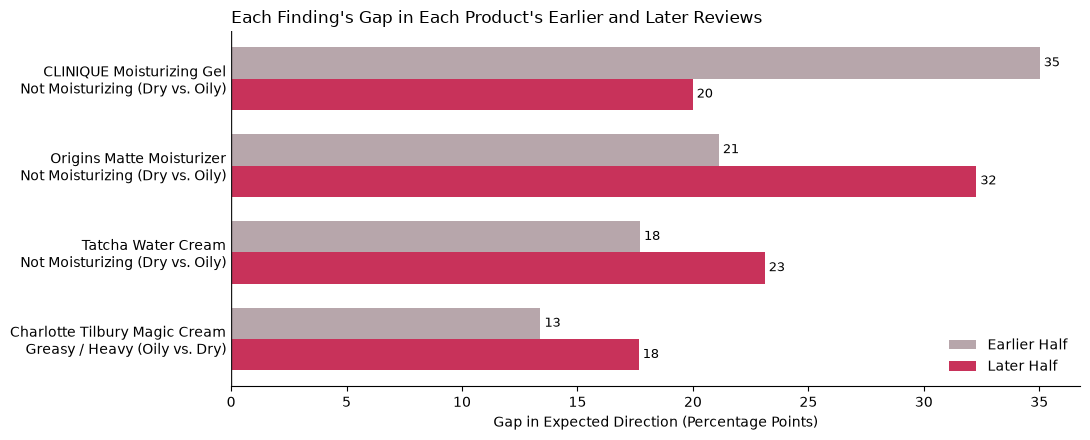

In [17]:
# Recompute each significant product-level gap in the earlier and later halves.
# Each product is split at its OWN median review date, so both halves have enough reviews
# (a single cutoff for all products left some halves with fewer than 10 reviews).
name_to_key = {v: k for k, v in CATEGORY_NAMES.items()}
findings = gaps[gaps["significant"]]

rows = []
for _, f in findings.iterrows():
    cat = name_to_key[f["complaint"]]
    # Expected direction: oily higher for greasy, dry higher for not moisturizing
    high, low = ("oily", "dry") if f["gap_pts"] > 0 else ("dry", "oily")
    product_reviews = labeled[labeled["product_label"] == f["product"]]
    product_cutoff = product_reviews["submission_time"].median()
    for period in ["earlier", "later"]:
        in_half = (product_reviews["submission_time"] < product_cutoff) == (period == "earlier")
        g = product_reviews[in_half]
        hi, lo = g[g["skin_type"] == high][cat], g[g["skin_type"] == low][cat]
        rows.append({"product": f["product"],
                     "complaint": f"{f['complaint']} ({high.title()} vs. {low.title()})",
                     "split_date": product_cutoff.date(), "period": period,
                     "higher_group_pct": hi.mean() * 100, "lower_group_pct": lo.mean() * 100,
                     "gap_pts": (hi.mean() - lo.mean()) * 100,
                     "n_higher": len(hi), "n_lower": len(lo)})
time_check = pd.DataFrame(rows)
display(time_check.round(1))

# Short display names, so product labels don't crowd out the bars
time_check["label"] = time_check["product"].map(short) + "\n" + time_check["complaint"]

# Grouped bar chart: each finding's gap in the earlier vs. later half, largest average gap at the top
gap_chart = time_check.pivot(index="label", columns="period", values="gap_pts")
gap_chart = gap_chart.loc[gap_chart.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(11, 4.5))
y = np.arange(len(gap_chart))
h = 0.36   # bar thickness
earlier = ax.barh(y + h / 2, gap_chart["earlier"], height=h, color="#B7A6AB", label="Earlier Half")
later = ax.barh(y - h / 2, gap_chart["later"], height=h, color="#C8325A", label="Later Half")
for bars in (earlier, later):
    ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
ax.axvline(0, color="#1A1A1A", linewidth=1)   # a bar left of this line would mean the gap reversed

ax.set_yticks(y, gap_chart.index, fontsize=10)
ax.set_title("Each Finding's Gap in Each Product's Earlier and Later Reviews", loc="left")
ax.set_xlabel("Gap in Expected Direction (Percentage Points)")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.savefig("../Figures/gap_chart.png", dpi=200, bbox_inches="tight")
plt.show()

**Observations**

All four product-level findings hold in both halves of each product's reviews. Splitting each product at its own median review date, every gap points the same direction in both halves:

| Product | Complaint | Earlier gap | Later gap |
|---|---|---|---|
| Clinique Moisturizing Gel | Not moisturizing (dry vs. oily) | 35 pts | 20 pts |
| Origins Matte Moisturizer | Not moisturizing (dry vs. oily) | 21 pts | 32 pts |
| Tatcha Water Cream | Not moisturizing (dry vs. oily) | 18 pts | 23 pts |
| Charlotte Tilbury Magic Cream | Greasy/heavy (oily vs. dry) | 13 pts | 18 pts |

Gap sizes vary between halves, which is expected with about 50 reviews per skin type in each, but none shrinks toward zero or reverses. Clinique's gap narrows the most (35 to 20 points) but remains the second largest. The findings are therefore not artifacts of a single period.

**The pooled pattern shows why product-level comparisons matter:** Splitting the whole sample at its median date (April 17, 2020), the greasy/heavy gap holds in both halves (oily vs. dry: 10.9% vs. 6.8% earlier, 13.2% vs. 6.5% later). The not-moisturizing gap, however, appears to shrink sharply (dry vs. oily: 15.6% vs. 4.7% earlier, but 7.6% vs. 5.5% later). This is a pooling artifact rather than a real change: the three light products behind the not-moisturizing findings were reviewed mostly in earlier years (their median review dates are 2014–2019), making up 24.8% of earlier-half reviews but only 5.2% of later-half reviews. Within each of those products, the gap persists in both halves. Comparing within products avoids drawing a false conclusion from changes in which products were being reviewed.

### 5.4 Validity Check: Do Labeled Complaints Match Star Ratings?

Claude labeled complaints from review text alone, without seeing star ratings. If the labels capture real problems, reviews tagged with a complaint should have noticeably lower ratings than reviews without it. This also shows how much each complaint hurts ratings, which helps prioritize recommendations: a complaint that drags ratings down sharply matters more than one reviewers mention in passing.

Average rating, all reviews: 4.33
Average rating, reviews with no complaint: 4.87
Average rating, reviews with any complaint: 3.36


,reviews_with,avg_rating_with,avg_rating_without,pct_1_2_star_with,pct_4_5_star_with,rating_drop
complaint,,,,,,
Breakouts,399,2.08,4.44,67.42,13.28,2.36
Irritation,187,2.39,4.37,53.48,21.93,1.99
Not Moisturizing,666,2.80,4.46,38.89,31.68,1.66
Reformulation,46,2.80,4.33,34.78,28.26,1.53
No Results,476,2.91,4.42,31.51,31.72,1.51
Pilling,91,2.86,4.34,41.76,35.16,1.49
Greasy / Heavy,783,3.22,4.44,28.61,47.64,1.22
Other,106,3.24,4.34,30.19,52.83,1.10
Fragrance,587,3.41,4.40,21.98,55.88,0.99


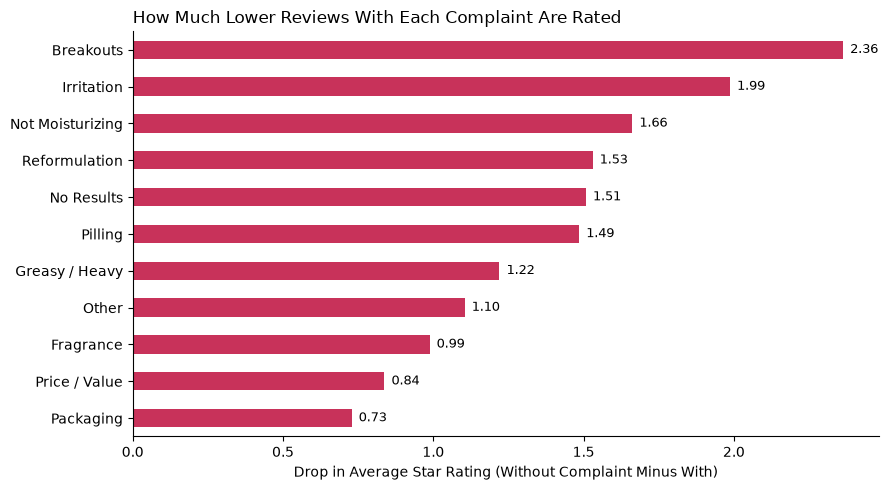

In [12]:
# Average star rating for reviews with vs. without each complaint
rows = []
for cat in CATEGORIES:
    has = labeled[cat] == 1
    rows.append({"complaint": CATEGORY_NAMES[cat],
                 "reviews_with": has.sum(),
                 "avg_rating_with": labeled.loc[has, "rating"].mean(),
                 "avg_rating_without": labeled.loc[~has, "rating"].mean(),
                 "pct_1_2_star_with": (labeled.loc[has, "rating"] <= 2).mean() * 100,
                 "pct_4_5_star_with": (labeled.loc[has, "rating"] >= 4).mean() * 100})
validity = pd.DataFrame(rows).set_index("complaint")
validity["rating_drop"] = validity["avg_rating_without"] - validity["avg_rating_with"]
validity = validity.sort_values("rating_drop", ascending=False)

# Baselines: average rating overall and for reviews with no complaint at all
print(f"Average rating, all reviews: {labeled['rating'].mean():.2f}")
print(f"Average rating, reviews with no complaint: {labeled.loc[labeled['any_complaint'] == 0, 'rating'].mean():.2f}")
print(f"Average rating, reviews with any complaint: {labeled.loc[labeled['any_complaint'] == 1, 'rating'].mean():.2f}")
display(validity.round(2))

# Bar chart: how many stars lower reviews with each complaint are rated, largest drop at the top
plot_barh(validity["rating_drop"], "How Much Lower Reviews With Each Complaint Are Rated",
          "Drop in Average Star Rating (Without Complaint Minus With)", fmt="{:.2f}",
          save_path="../Figures/rating_drop_by_complaint.png")

**Observations**

**Claude's labels line up with star ratings:** Reviews with no labeled complaint average **4.87 stars**, while reviews with at least one complaint average 3.36, a gap of 1.5 stars. Every complaint category is associated with a lower rating, even though Claude never saw the ratings. This supports the agreement test in Section 4: the labels capture real dissatisfaction, not noise.

**Complaints Fall into Two Groups:**
- Deal-breakers: Breakouts (average rating 2.08, with 67% of these reviews rated 1–2 stars), irritation (2.39), and not moisturizing (2.80) are linked to the largest drops, 1.7 to 2.4 stars. When a product breaks a reviewer out, irritates their skin, or fails to moisturize, they usually rate it poorly.
- Annoyances: Greasy/heavy (3.22), fragrance (3.41), price/value (3.56), and packaging (3.62) are linked to smaller drops of 0.7 to 1.2 stars. About half or more of these complaints appear in 4–5 star reviews (48% for greasy/heavy, 56–63% for fragrance, price, and packaging): reviewers often mention them as drawbacks of a product they still like.

**What this means for the findings:** Three of the four product-level findings (Section 5.2) involve not moisturizing, a deal-breaker complaint, so steering dry-skin shoppers away from those products addresses a problem that substantially lowers satisfaction. The greasy/heavy finding (Charlotte Tilbury Magic Cream) involves a milder complaint, so it is a lower priority, though still worth acting on given the size of the gap. Breakouts have the largest rating drop of any complaint but showed no confirmed skin-type gap at the product level, which suggests they depend more on the individual than on skin type, and are better addressed through ingredient filters than skin-type quiz rules.

**Caveats:** These are associations, not causes. Many reviews contain several complaints, so each category's drop partly reflects the others. Rates for irritation and no results are upper bounds (Claude over-applied them in the agreement test), and reformulation (46 reviews) and pilling (91) have small samples.

### 5.5 Which products work across skin types?

A product with no gap between skin types isn't necessarily a good fit for everyone: it could be equally poor for all of them. So "works across skin types" is defined more strictly here. For each product, the skin-fit complaint rate is the share of reviews mentioning at least one of greasy/heavy, not moisturizing, or breakouts, the three complaints most tied to how a product suits the skin. A product works across skin types if even its worst skin type has a skin-fit complaint rate below the average across the whole sample.

With about 100 reviews per product and skin type, these rates carry some uncertainty (roughly ±6–8 percentage points), so products close to the line are better described as candidates than as confirmed.

Average skin-fit complaint rate across the sample: 20.0%


skin_type,Dry,Normal,Combination,Oily,worst_skin_type,worst_rate,works_for_all
product_label,,,,,,,
KORRES – Santorini Grape Poreless Skin,12.0,10.0,13.0,8.0,Combination,13.0,True
IT Cosmetics – Confidence in a Cream,13.0,9.0,14.1,12.0,Combination,14.1,True
First Aid Beauty – Ultra Repair Cream Intense,12.0,12.0,15.0,12.0,Combination,15.0,True
belif – The True Cream Moisturizing,14.0,13.0,16.0,15.0,Combination,16.0,True
Estée Lauder – Revitalizing Supreme+ Youth Power,16.0,11.0,17.0,15.0,Combination,17.0,True
KORRES – Greek Yoghurt Nourishing Probiotic,17.0,14.0,13.0,14.1,Dry,17.0,True
belif – The True Cream Aqua,14.0,16.0,10.0,19.0,Oily,19.0,True
OLEHENRIKSEN – C-Rush Vitamin C Gel,13.0,18.0,20.0,21.0,Oily,21.0,False
Charlotte Tilbury – Magic Cream Moisturizer,8.0,9.0,17.0,22.0,Oily,22.0,False


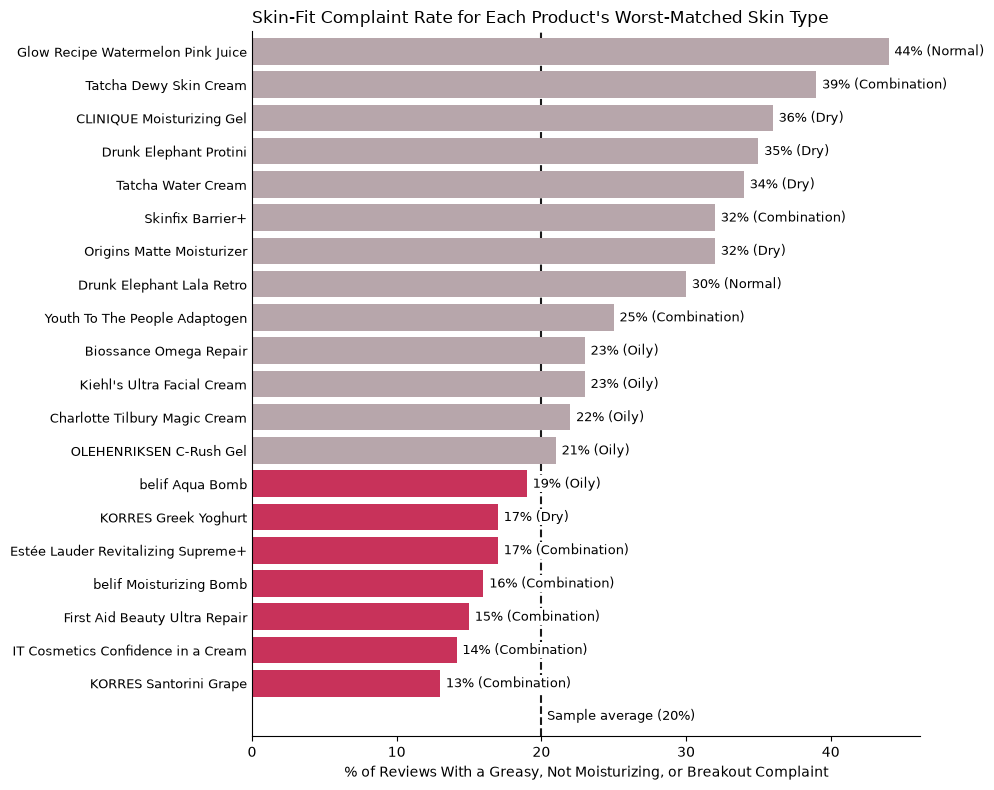

In [18]:
# Skin-fit complaint: the review mentions greasy/heavy, not moisturizing, or breakouts
labeled["skin_fit_complaint"] = labeled[FOCUS].max(axis=1)
average_rate = labeled["skin_fit_complaint"].mean() * 100
print(f"Average skin-fit complaint rate across the sample: {average_rate:.1f}%")

# Skin-fit complaint rate for every product and skin type, plus each product's worst skin type
fit = (labeled.groupby(["product_label", "skin_type"])["skin_fit_complaint"].mean() * 100).unstack()[SKIN_ORDER]
fit["worst_skin_type"] = fit[SKIN_ORDER].idxmax(axis=1).map(SKIN_LABELS)
fit["worst_rate"] = fit[SKIN_ORDER].max(axis=1)
fit["works_for_all"] = fit["worst_rate"] < average_rate
fit = fit.sort_values("worst_rate")
display(fit.rename(columns=SKIN_LABELS).round(1))

# Bar chart: each product's worst-skin-type rate; products below the average line work for all skin types
fig, ax = plt.subplots(figsize=(10, 8))
colors = ["#C8325A" if w else "#B7A6AB" for w in fit["works_for_all"]]
ax.barh([short(p) for p in fit.index], fit["worst_rate"], color=colors)
# Average line drawn behind the labels, with its label below the bars so nothing overlaps
ax.axvline(average_rate, color="#1A1A1A", linewidth=1.5, linestyle="--", zorder=0)
ax.text(average_rate + 0.4, -1.1, f"Sample average ({average_rate:.0f}%)", fontsize=9)
for i, (rate, skin) in enumerate(zip(fit["worst_rate"], fit["worst_skin_type"])):
    # White background behind each label so the dashed line doesn't cut through the text
    ax.text(rate + 0.4, i, f"{rate:.0f}% ({skin})", va="center", fontsize=9, zorder=3,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_ylim(-1.6, len(fit) - 0.4)   # room below the bars for the average label
ax.set_title("Skin-Fit Complaint Rate for Each Product's Worst-Matched Skin Type", loc="left")
ax.set_xlabel("% of Reviews With a Greasy, Not Moisturizing, or Breakout Complaint")
ax.tick_params(axis="y", labelsize=9, length=0)
clean_axes(ax)
plt.tight_layout()
plt.savefig("../Figures/works_for_all_skin_types.png", dpi=200, bbox_inches="tight")
plt.show()

  ## 6. Key Findings

  ## 7. Business Implications and Recommendations

  ## 8. Ethical and Privacy Considerations